<a href="https://colab.research.google.com/github/citlalli-carpintero/Examen_fcd_u2/blob/main/ExamenU2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Integradora — Unidad 2
## Inferencia Estadística y Toma de Decisiones en Ingeniería
**Caso A — Arquitectura de Software: Monolito vs. Microservicios**


## 0. Configuración y obtención del dataset

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# ---- Parámetros globales -------------------------------------------------
SEED = 42            # reproducibilidad
ALPHA = 0.05         # nivel de significancia
COL_Y, COL_X = "latencia_ms", "grupo"
GRUPOS = ["Monolito", "Microservicios"]
COLORES = {"Monolito": "#1f77b4", "Microservicios": "#d62728"}

DATA_DIR = Path("../data")
FIG_DIR = Path("../docs/figs")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 160)
print("NumPy", np.__version__, "| pandas", pd.__version__, "| SciPy", __import__("scipy").__version__)

NumPy 2.1.3 | pandas 2.2.3 | SciPy 1.16.3


In [ ]:
# Script base de la actividad (Listing 1) — Caso A
np.random.seed(42)
n = 250

lat_monolito  = np.random.gamma(shape=2.5, scale=35, size=n) + 40
lat_microserv = np.random.gamma(shape=2.2, scale=40, size=n) + 45

df_gen = pd.DataFrame({
    "latencia_ms": np.concatenate([lat_monolito, lat_microserv]),
    "grupo": ["Monolito"] * n + ["Microservicios"] * n,
})
df_gen.to_csv(DATA_DIR / "dataset_caso_a.csv", index=False)
print(f"Dataset original guardado: {DATA_DIR / 'dataset_caso_a.csv'}  ->  {df_gen.shape[0]} filas")

Dataset original guardado: ../data/dataset_caso_a.csv  ->  500 filas


---
## Bloque 1 — Estadística descriptiva y limpieza

### 1.1 Carga, tipos de datos y valores ausentes

In [ ]:
def cargar_datos(ruta):
    #Carga el CSV y tipa la variable cualitativa como categórica ordenada.
    d = pd.read_csv(ruta)
    d[COL_X] = pd.Categorical(d[COL_X], categories=GRUPOS, ordered=True)
    return d

df = cargar_datos(DATA_DIR / "dataset_caso_a.csv")

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes.to_string())
print("\nValores ausentes por columna:")
print(df.isna().sum().to_string())
print("\nObservaciones por grupo:")
print(df[COL_X].value_counts().to_string())
print("\nDuplicados exactos:", df.duplicated().sum())
df.head()

Dimensiones: (500, 2)

Tipos de datos:
latencia_ms     float64
grupo          category

Valores ausentes por columna:
latencia_ms    0
grupo          0

Observaciones por grupo:
grupo
Monolito          250
Microservicios    250

Duplicados exactos: 0


,latencia_ms,grupo
0,144.410,Monolito
1,108.931,Monolito
2,104.398,Monolito
3,104.399,Monolito
4,229.756,Monolito


### 1.2 Detección y remoción de valores atípicos (criterio $1.5\times$IQR)

In [ ]:
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr, q1, q3, iqr


def depurar_iqr(d, col, grupo, k=1.5):
    #Elimina outliers por grupo; devuelve (df_depurado, tabla_resumen).
    mantener = pd.Series(True, index=d.index)
    filas = []
    for g, sub in d.groupby(grupo, observed=True):
        lo, hi, q1, q3, iqr = limites_iqr(sub[col], k)
        fuera = (sub[col] < lo) | (sub[col] > hi)
        mantener.loc[sub.index[fuera]] = False
        filas.append({"grupo": g, "n_inicial": len(sub), "Q1": q1, "Q3": q3, "IQR": iqr,
                      "lim_inf": lo, "lim_sup": hi, "outliers": int(fuera.sum()),
                      "n_final": int((~fuera).sum())})
    return d[mantener].copy(), pd.DataFrame(filas).set_index("grupo")


df_clean, tabla_outliers = depurar_iqr(df, COL_Y, COL_X)
df_clean.to_csv(DATA_DIR / "dataset_caso_a_depurado.csv", index=False)

print(tabla_outliers.to_string())
print(f"\nTotal removidos: {len(df) - len(df_clean)}  ({(len(df)-len(df_clean))/len(df):.1%})")
print(f"N depurado = {len(df_clean)}  (requisito: N >= 400 y n >= 200 por grupo)")
assert len(df_clean) >= 400 and (df_clean[COL_X].value_counts() >= 200).all()

                n_inicial     Q1      Q3    IQR  lim_inf  lim_sup  outliers  n_final
grupo                                                                               
Monolito              250 90.376 154.484 64.108   -5.787  250.646        10      240
Microservicios        250 89.959 158.171 68.212  -12.359  260.488         7      243

Total removidos: 17  (3.4%)
N depurado = 483  (requisito: N >= 400 y n >= 200 por grupo)


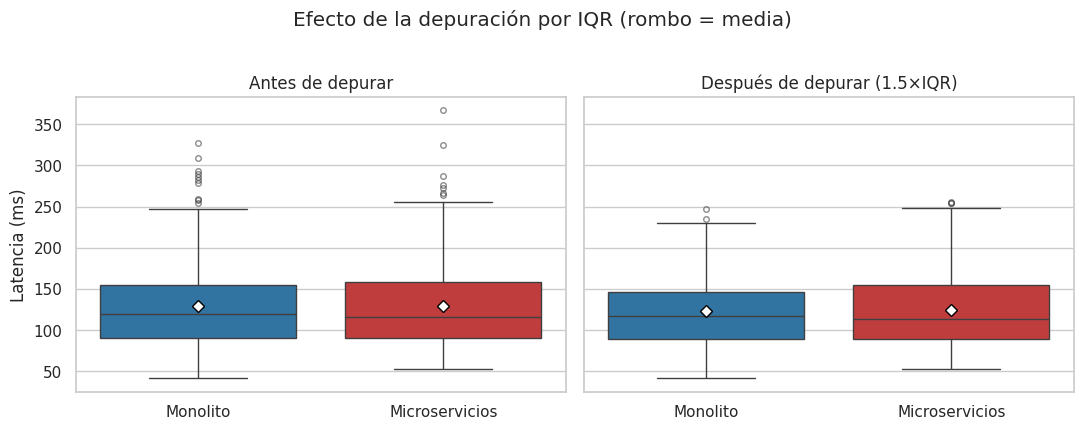

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, d, tit in zip(axes, [df, df_clean], ["Antes de depurar", "Después de depurar (1.5×IQR)"]):
    sns.boxplot(data=d, x=COL_X, y=COL_Y, hue=COL_X, palette=COLORES, showmeans=True,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"),
                flierprops=dict(marker="o", markersize=4, alpha=.6), legend=False, ax=ax)
    ax.set_title(tit); ax.set_xlabel(""); ax.set_ylabel("Latencia (ms)")
fig.suptitle("Efecto de la depuración por IQR (rombo = media)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_outliers.png", dpi=150, bbox_inches="tight")

### 1.3 Media muestral (x̄), mediana, desviación estándar (s), varianza (s²), asimetría y curtosis.

In [ ]:
def resumen_descriptivo(x):
    x = np.asarray(x, dtype=float)
    return pd.Series({
        "n": len(x),
        "media (x̄)": x.mean(),
        "mediana": np.median(x),
        "desv. est. (s)": x.std(ddof=1),
        "varianza (s²)": x.var(ddof=1),
        "asimetría (G1)": stats.skew(x, bias=False),
        "curtosis exceso (G2)": stats.kurtosis(x, bias=False),
    })

tabla_desc = df_clean.groupby(COL_X, observed=True)[COL_Y].apply(resumen_descriptivo).unstack()
tabla_desc.loc["Global"] = resumen_descriptivo(df_clean[COL_Y])
tabla_desc

,n,media (x̄),mediana,desv. est. (s),varianza (s²),asimetría (G1),curtosis exceso (G2)
grupo,,,,,,,
Monolito,240.000,123.200,117.012,43.529,"1,894.787",0.620,-0.137
Microservicios,243.000,124.614,113.969,48.204,"2,323.634",0.775,-0.071
Global,483.000,123.911,116.293,45.898,"2,106.670",0.715,-0.067


### 1.4 Histogramas con KDE y diagramas de caja comparativos

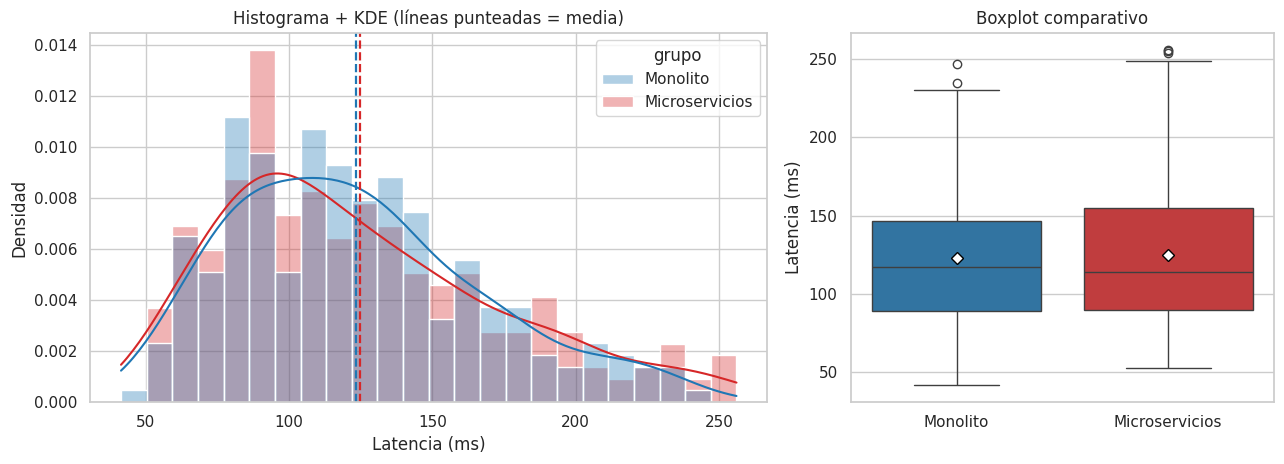

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

# (a) Histogramas + KDE superpuestos (densidad, para comparar con n distintos)
sns.histplot(data=df_clean, x=COL_Y, hue=COL_X, hue_order=GRUPOS, palette=COLORES, kde=True,
             stat="density", common_norm=False, bins=24, alpha=.35, edgecolor="white", ax=axes[0])
for g in GRUPOS:
    m = df_clean.loc[df_clean[COL_X] == g, COL_Y].mean()
    axes[0].axvline(m, color=COLORES[g], ls="--", lw=1.6)
axes[0].set(title="Histograma + KDE (líneas punteadas = media)", xlabel="Latencia (ms)", ylabel="Densidad")

# (b) Boxplot comparativo
sns.boxplot(data=df_clean, x=COL_X, y=COL_Y, hue=COL_X, palette=COLORES, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"),
            legend=False, ax=axes[1])
axes[1].set(title="Boxplot comparativo", xlabel="", ylabel="Latencia (ms)")

fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_descriptivo.png", dpi=150, bbox_inches="tight")

---
## Bloque 2 — Distribuciones de muestreo y Teorema Central del Límite


### 2.1 Muestra global

In [21]:
y = df_clean[COL_Y].to_numpy()
N = len(y)
s_global = y.std(ddof=1)
mu_global = y.mean()
print(f"N = {N}  |  media = {mu_global:.3f} ms  |  s = {s_global:.3f} ms  |  asimetría (poblacional) = {stats.skew(y):.3f}")
assert N >= 400

N = 483  |  media = 123.911 ms  |  s = 45.898 ms  |  asimetría (poblacional) = 0.712


### 2.2 Remuestreo con reemplazo ($k = 1000$) para $n \in \{5, 15, 30, 60\}$

In [22]:
TAMANOS = [5, 15, 30, 60]
K = 1000

def remuestreo_medias(x, n, k=K, rng=None):
    #k medias de muestras de tamaño n, con reemplazo.
    idx = rng.integers(0, len(x), size=(k, n))
    return x[idx].mean(axis=1)

rng = np.random.default_rng(SEED)
medias = {n: remuestreo_medias(y, n, K, rng) for n in TAMANOS}
print({n: m.shape for n, m in medias.items()})

{5: (1000,), 15: (1000,), 30: (1000,), 60: (1000,)}


### 2.3 Cuadrícula 2×2 de las distribuciones de medias muestrales

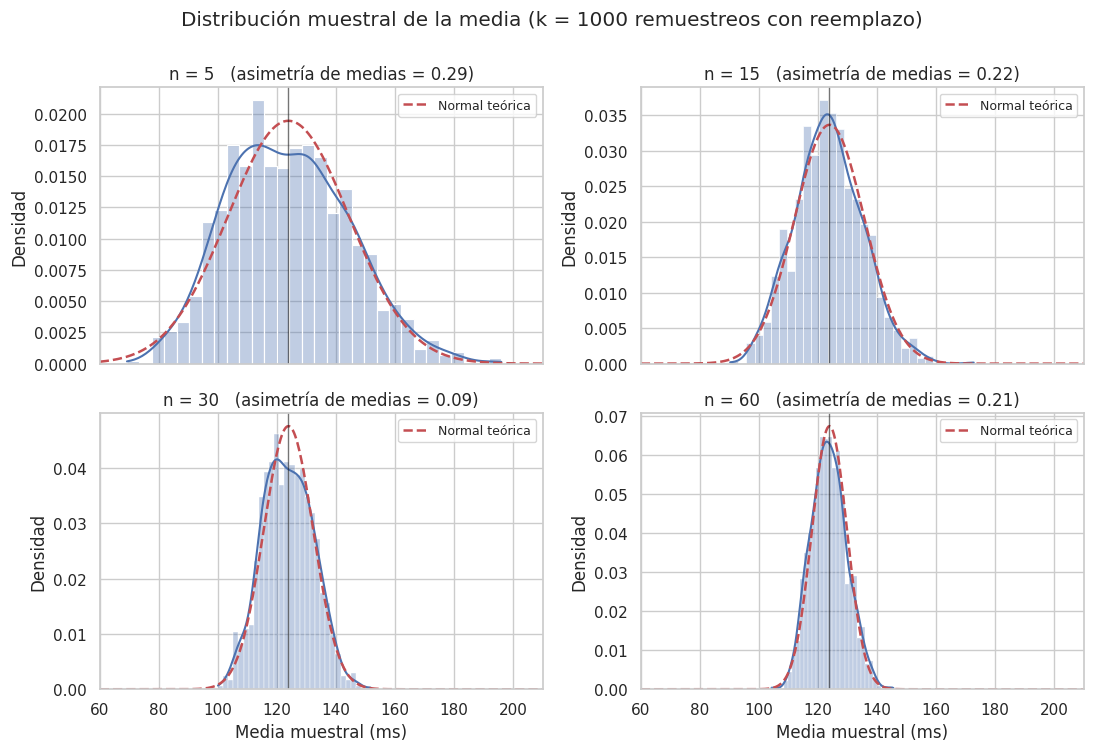

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
xs = np.linspace(60, 210, 400)
for ax, n in zip(axes.ravel(), TAMANOS):
    m = medias[n]
    sns.histplot(m, stat="density", bins=30, kde=True, color="#4c72b0", alpha=.35, edgecolor="white", ax=ax)
    ax.plot(xs, stats.norm.pdf(xs, mu_global, s_global / np.sqrt(n)), "r--", lw=1.8, label="Normal teórica")
    ax.axvline(mu_global, color="k", lw=1, alpha=.6)
    ax.set_title(f"n = {n}   (asimetría de medias = {stats.skew(m):.2f})")
    ax.set_xlabel("Media muestral (ms)"); ax.set_ylabel("Densidad")
    ax.legend(loc="upper right", fontsize=9)
axes[0, 0].set_xlim(60, 210)
fig.suptitle("Distribución muestral de la media (k = 1000 remuestreos con reemplazo)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_tlc.png", dpi=150, bbox_inches="tight")

### 2.4 Error estándar empírico vs. teórico

- **Empírico:** desviación estándar de las $k=1000$ medias, $\widehat{\sigma}_{\bar{x}}$.
- **Teórico:** $\sigma_{\bar{x}} = s/\sqrt{n}$, con $s$ la desviación estándar de la muestra global.
- Además se compara la **asimetría** de las medias con la predicha por teoría: $\gamma_{\bar{X}} = \gamma_X/\sqrt{n}$, y se aplica la prueba de normalidad de Shapiro–Wilk.

In [24]:
g1_pob = stats.skew(y)  # asimetría poblacional de la muestra global
filas = []
for n in TAMANOS:
    m = medias[n]
    se_emp, se_teo = m.std(ddof=1), s_global / np.sqrt(n)
    filas.append({
        "n": n,
        "media de medias": m.mean(),
        "SE empírico": se_emp,
        "SE teórico (s/√n)": se_teo,
        "error relativo (%)": 100 * (se_emp - se_teo) / se_teo,
        "asimetría medias": stats.skew(m),
        "asimetría teórica (γ/√n)": g1_pob / np.sqrt(n),
        "Shapiro-Wilk p": stats.shapiro(m).pvalue,
    })
tabla_tlc = pd.DataFrame(filas).set_index("n")
print(f"Media global (referencia) = {mu_global:.3f} ms | s global = {s_global:.3f} ms\n")
tabla_tlc

Media global (referencia) = 123.911 ms | s global = 45.898 ms



,media de medias,SE empírico,SE teórico (s/√n),error relativo (%),asimetría medias,asimetría teórica (γ/√n),Shapiro-Wilk p
n,,,,,,,
5,123.827,20.454,20.526,-0.355,0.287,0.319,0.000
15,123.649,11.495,11.851,-3.003,0.216,0.184,0.011
30,123.648,8.514,8.380,1.605,0.088,0.130,0.029
60,123.749,6.055,5.925,2.186,0.207,0.092,0.014


---
## Bloque 3 — Estimación por intervalos de confianza

### 3.1 IC para la media poblacional general ($\mu$) al 90 %, 95 % y 99 %

In [25]:
def ic_media(x, conf, dist="t"):
    x = np.asarray(x, dtype=float)
    n, m, se = len(x), x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    crit = stats.t.ppf(1 - (1 - conf) / 2, n - 1) if dist == "t" else stats.norm.ppf(1 - (1 - conf) / 2)
    return m - crit * se, m + crit * se, crit

filas = []
for conf in (0.90, 0.95, 0.99):
    lo_t, hi_t, c_t = ic_media(y, conf, "t")
    lo_z, hi_z, c_z = ic_media(y, conf, "z")
    # verificación independiente con scipy
    lo_s, hi_s = stats.t.interval(conf, len(y) - 1, loc=y.mean(), scale=stats.sem(y))
    assert np.allclose([lo_t, hi_t], [lo_s, hi_s])
    filas.append({"confianza": f"{conf:.0%}", "t crítico": c_t, "z crítico": c_z,
                  "IC t: inferior": lo_t, "IC t: superior": hi_t,
                  "IC z: inferior": lo_z, "IC z: superior": hi_z,
                  "amplitud (t)": hi_t - lo_t})
tabla_ic_mu = pd.DataFrame(filas).set_index("confianza")
print(f"n = {len(y)}, media = {y.mean():.3f} ms, error estándar = {stats.sem(y):.3f} ms\n")
tabla_ic_mu

n = 483, media = 123.911 ms, error estándar = 2.088 ms



,t crítico,z crítico,IC t: inferior,IC t: superior,IC z: inferior,IC z: superior,amplitud (t)
confianza,,,,,,,
90%,1.648,1.645,120.470,127.353,120.476,127.347,6.884
95%,1.965,1.960,119.808,128.015,119.818,128.005,8.207
99%,2.586,2.576,118.511,129.312,118.532,129.291,10.802


### 3.2 IC del 95 % para la diferencia de medias $(\mu_1-\mu_2)$

In [26]:
mono  = df_clean.loc[df_clean[COL_X] == "Monolito", COL_Y].to_numpy()
micro = df_clean.loc[df_clean[COL_X] == "Microservicios", COL_Y].to_numpy()
print(f"n_mono = {len(mono)}, n_micro = {len(micro)}")

lev_stat, lev_p = stats.levene(mono, micro, center="median")
varianzas_iguales = lev_p >= ALPHA
print(f"Levene (center=median): W = {lev_stat:.4f}, p = {lev_p:.4f}")
print(f"Razón de varianzas s²_micro / s²_mono = {micro.var(ddof=1) / mono.var(ddof=1):.3f}")
print("->", "No se rechaza H0: varianzas homogéneas -> IC con varianza combinada (pooled)"
      if varianzas_iguales else "Se rechaza H0: varianzas distintas -> IC con corrección de Welch")

n_mono = 240, n_micro = 243
Levene (center=median): W = 1.8419, p = 0.1754
Razón de varianzas s²_micro / s²_mono = 1.226
-> No se rechaza H0: varianzas homogéneas -> IC con varianza combinada (pooled)


In [27]:
def ic_diferencia(x1, x2, conf=0.95, varianzas_iguales=False):
    #IC para mu1 - mu2 (pooled o Welch). Devuelve dict con diferencia, IC, SE y gl.
    n1, n2 = len(x1), len(x2)
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    if varianzas_iguales:
        sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
        se, gl = np.sqrt(sp2 * (1 / n1 + 1 / n2)), n1 + n2 - 2
    else:
        se = np.sqrt(v1 / n1 + v2 / n2)
        gl = se**4 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    crit = stats.t.ppf(1 - (1 - conf) / 2, gl)
    d = x1.mean() - x2.mean()
    return {"dif": d, "inf": d - crit * se, "sup": d + crit * se, "se": se, "gl": gl, "t_crit": crit}

# Ambos métodos (comparación) y el elegido por Levene
ic_pooled = ic_diferencia(mono, micro, 0.95, True)
ic_welch  = ic_diferencia(mono, micro, 0.95, False)
ic_dif = ic_pooled if varianzas_iguales else ic_welch
metodo = "pooled (varianzas combinadas)" if varianzas_iguales else "Welch"

# Verificación independiente con SciPy
chk = stats.ttest_ind(mono, micro, equal_var=varianzas_iguales).confidence_interval(0.95)
assert np.allclose([ic_dif["inf"], ic_dif["sup"]], [chk.low, chk.high])

comp = pd.DataFrame({"pooled": ic_pooled, "Welch": ic_welch}).T[["dif", "inf", "sup", "se", "gl"]]
print("Comparación de métodos (IC 95 % de μ1 − μ2, μ1 = Monolito, μ2 = Microservicios):")
print(comp.to_string())
print(f"\nMétodo elegido: {metodo}")
print(f"IC 95 %: [{ic_dif['inf']:.3f}, {ic_dif['sup']:.3f}] ms   (diferencia puntual = {ic_dif['dif']:.3f} ms)")

Comparación de métodos (IC 95 % de μ1 − μ2, μ1 = Monolito, μ2 = Microservicios):
          dif    inf   sup    se      gl
pooled -1.415 -9.630 6.800 4.181 481.000
Welch  -1.415 -9.625 6.795 4.178 477.197

Método elegido: pooled (varianzas combinadas)
IC 95 %: [-9.630, 6.800] ms   (diferencia puntual = -1.415 ms)


### 3.3 ¿Pertenece el cero al intervalo? ($0\in$ IC):

IC 95 % = [-9.630, 6.800]  ->  ¿0 ∈ IC? True


,inferior,superior,¿0 ∈ IC?
confianza,,,
80%,-6.780,3.951,True
90%,-8.305,5.475,True
95%,-9.630,6.800,True
99%,-12.227,9.397,True


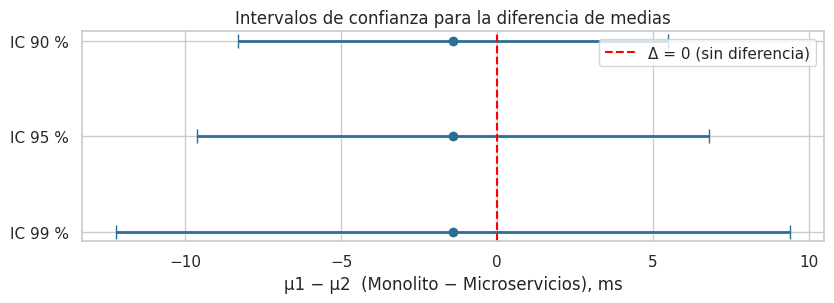

In [28]:
cero_en_ic = ic_dif["inf"] <= 0 <= ic_dif["sup"]
print(f"IC 95 % = [{ic_dif['inf']:.3f}, {ic_dif['sup']:.3f}]  ->  ¿0 ∈ IC? {cero_en_ic}")

# Sensibilidad a la confianza (mismo método)
filas = []
for conf in (0.80, 0.90, 0.95, 0.99):
    r = ic_diferencia(mono, micro, conf, varianzas_iguales)
    filas.append({"confianza": f"{conf:.0%}", "inferior": r["inf"], "superior": r["sup"],
                  "¿0 ∈ IC?": r["inf"] <= 0 <= r["sup"]})
tabla_ic_sens = pd.DataFrame(filas).set_index("confianza")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, conf in enumerate((0.99, 0.95, 0.90)):
    r = ic_diferencia(mono, micro, conf, varianzas_iguales)
    ax.errorbar(r["dif"], i, xerr=[[r["dif"] - r["inf"]], [r["sup"] - r["dif"]]], fmt="o", capsize=5, lw=2,
                color="#2a6f97")
ax.axvline(0, color="red", ls="--", label="Δ = 0 (sin diferencia)")
ax.set_yticks(range(3)); ax.set_yticklabels(["IC 99 %", "IC 95 %", "IC 90 %"])
ax.set_xlabel("μ1 − μ2  (Monolito − Microservicios), ms"); ax.legend()
ax.set_title("Intervalos de confianza para la diferencia de medias")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_ic_diferencia.png", dpi=150, bbox_inches="tight")
tabla_ic_sens

---
## Bloque 4 — Teoría de decisión (prueba de hipótesis)

### 4.1 Planteamiento formal de hipótesis



### 4.2 Matriz de decisión y costos de los errores


### 4.3 Nivel de significancia
Se fija $\alpha = 0.05$ (ya definido en `ALPHA`): la probabilidad máxima tolerada de concluir que los microservicios son más lentos cuando en realidad no lo son.

### 4.4 Prueba paramétrica `scipy.stats.ttest_ind`

In [29]:
# Prueba principal: unilateral, H1: mu_micro > mu_mono
res = stats.ttest_ind(micro, mono, equal_var=varianzas_iguales, alternative="greater")
# Referencia: bilateral (consistente con el IC del Bloque 3)
res_2s = stats.ttest_ind(micro, mono, equal_var=varianzas_iguales, alternative="two-sided")

gl = res.df
t_crit = stats.t.ppf(1 - ALPHA, gl)
d_obs = micro.mean() - mono.mean()

# Tamaño del efecto (d de Cohen con desviación combinada)
sp = np.sqrt(((len(mono) - 1) * mono.var(ddof=1) + (len(micro) - 1) * micro.var(ddof=1)) / (len(mono) + len(micro) - 2))
cohen_d = d_obs / sp

# Verificación manual del estadístico
t_manual = d_obs / ic_dif["se"]
assert np.isclose(t_manual, res.statistic)

print(f"Método: {'t de Student (varianzas iguales)' if varianzas_iguales else 't de Welch (varianzas distintas)'}")
print(f"Diferencia observada (micro - mono) = {d_obs:.3f} ms")
print(f"Estadístico t         = {res.statistic:.4f}   (gl = {gl:.1f})")
print(f"Valor crítico (α=0.05, 1 cola) = {t_crit:.4f}")
print(f"p-value (unilateral)  = {res.pvalue:.4f}")
print(f"p-value (bilateral, referencia) = {res_2s.pvalue:.4f}")
print(f"d de Cohen            = {cohen_d:.3f}")

Método: t de Student (varianzas iguales)
Diferencia observada (micro - mono) = 1.415 ms
Estadístico t         = 0.3384   (gl = 481.0)
Valor crítico (α=0.05, 1 cola) = 1.6480
p-value (unilateral)  = 0.3676
p-value (bilateral, referencia) = 0.7352
d de Cohen            = 0.031


### 4.5 Potencia ($1-\beta$) y efecto mínimo detectable

In [30]:
se_w = np.sqrt(mono.var(ddof=1) / len(mono) + micro.var(ddof=1) / len(micro))
gl_w = se_w**4 / ((mono.var(ddof=1) / len(mono)) ** 2 / (len(mono) - 1) + (micro.var(ddof=1) / len(micro)) ** 2 / (len(micro) - 1))
tc = stats.t.ppf(1 - ALPHA, gl_w)

def potencia(delta):
    return 1 - stats.nct.cdf(tc, gl_w, delta / se_w)

deltas = [2.5, 5, 10, 15, 20, 30]
tabla_potencia = pd.DataFrame({"Δ real (ms)": deltas,
                               "potencia (1-β)": [potencia(d) for d in deltas],
                               "β (Error Tipo II)": [1 - potencia(d) for d in deltas]}).set_index("Δ real (ms)")
mde80 = (stats.t.ppf(1 - ALPHA, gl_w) + stats.t.ppf(0.80, gl_w)) * se_w
print(f"Error estándar de la diferencia = {se_w:.3f} ms")
print(f"Efecto mínimo detectable (potencia 80 %, α = 0.05, 1 cola) ≈ {mde80:.1f} ms\n")
tabla_potencia

Error estándar de la diferencia = 4.178 ms
Efecto mínimo detectable (potencia 80 %, α = 0.05, 1 cola) ≈ 10.4 ms



,potencia (1-β),β (Error Tipo II)
Δ real (ms),,
2.500,0.147,0.853
5.000,0.326,0.674
10.000,0.772,0.228
15.000,0.974,0.026
20.000,0.999,0.001
30.000,1.000,0.000


### 4.6 Veredicto formal y recomendación técnica

In [31]:
rechazar = res.pvalue < ALPHA
veredicto = "RECHAZAR H0" if rechazar else "NO RECHAZAR H0"
print(f"Regla: rechazar H0 si p-value < α  ->  {res.pvalue:.4f} {'<' if rechazar else '>='} {ALPHA}")
print(f"VEREDICTO: {veredicto}")

Regla: rechazar H0 si p-value < α  ->  0.3676 >= 0.05
VEREDICTO: NO RECHAZAR H0


---
## 5. Conclusiones

In [32]:
# Resumen final reproducible de resultados clave
resumen = {
    "N total depurado": len(df_clean),
    "n monolito / microservicios": f"{len(mono)} / {len(micro)}",
    "media monolito (ms)": round(mono.mean(), 2),
    "media microservicios (ms)": round(micro.mean(), 2),
    "Levene p": round(lev_p, 4),
    "IC 95 % (mu1 - mu2)": (round(ic_dif["inf"], 2), round(ic_dif["sup"], 2)),
    "0 en IC": bool(cero_en_ic),
    "t (1 cola)": round(res.statistic, 3),
    "p-value (1 cola)": round(res.pvalue, 4),
    "veredicto": veredicto,
}
pd.Series(resumen)

,0
N total depurado,483
n monolito / microservicios,240 / 243
media monolito (ms),123.200
media microservicios (ms),124.610
Levene p,0.175
IC 95 % (mu1 - mu2),"(-9.63, 6.8)"
0 en IC,True
t (1 cola),0.338
p-value (1 cola),0.368
veredicto,NO RECHAZAR H0
